# 5. Rasters and zonal statistics

`zonal_stats` summarizes a raster's cells under each zone. Two rules decide which cells count:

- **`cell_coverage`** (the default, using exactextract): every cell the zone touches, weighted by
  the fraction of the cell it covers. Exact for small zones and ragged edges.
- **`cell_center`**: a cell counts wholly if its centre is inside the zone (the rule of GDAL,
  rasterstats and Curio). Faster, but small zones can miss most of their cells.

The result also reports **coverage**: how much of each zone the raster covers, and how much of it
has valid values.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import urbanweave as uw

import tutorial_data as td          # Riverton, the synthetic town these tutorials use
from svgmap import Map              # small static SVG maps
from tutorial_data import show      # prints reports compactly
import diagrams                     # schematic figures of the concepts

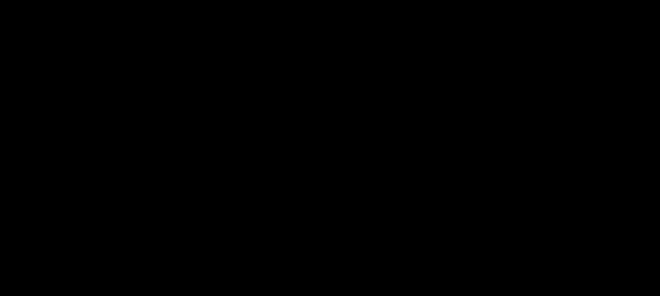

In [2]:
diagrams.zonal_rules()

In [3]:
districts = td.districts()
tracts = td.tracts()
heat = td.heat()            # UTCI in °C, 10 m cells, with a sensor gap
land = td.land_cover()      # 1 built, 2 green, 3 water
show(heat.describe())

{
 "crs": "EPSG:32618",
 "width": 300,
 "height": 200,
 "transform": [10.0, 0.0, 498500.0, 0.0, -10.0, 4501000.0],
 "bands": [
  {
   "index": 1,
   "name": "utci",
   "nodata": null,
   "scale": 1.0,
   "offset": 0.0,
   "value_kind": "intensive",
   "units": "degC"
  }
 ]
}


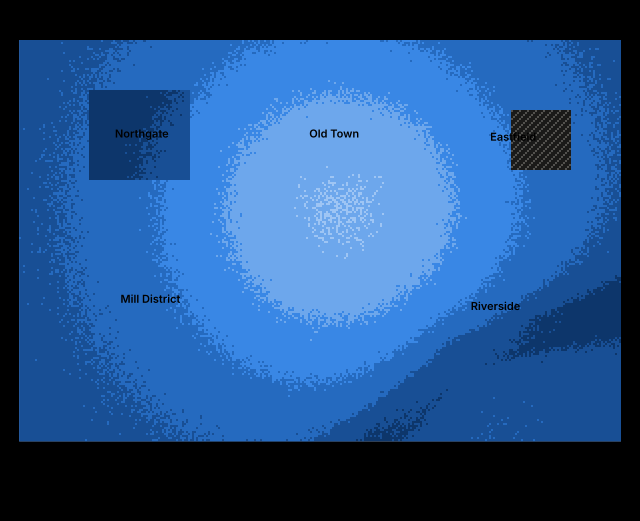

In [4]:
(Map("Universal Thermal Climate Index (UTCI), 10 m cells")
 .raster(heat, legend="UTCI (°C)")
 .outline(districts, label="name", width=1.4)
 .note("Hatched: a sensor gap (nodata). Synthetic data."))

## Heat by district

The mean, minimum and maximum UTCI per district. Eastfield's `valid_coverage` is below 1: part of
it lies in the sensor gap, and its mean is taken over the valid cells only.

In [5]:
hot = uw.zonal_stats(heat, districts, [
    uw.mean("utci", as_="utci_mean"), uw.min("utci", as_="utci_min"), uw.max("utci", as_="utci_max"),
], zone_id="district_id")
hot.drop(columns="geometry").round(2)

,district_id,name,utci_mean,utci_min,utci_max,coverage,valid_coverage
0,NG,Northgate,28.64,24.14,32.96,1.0,1.0
1,OT,Old Town,32.8,29.89,34.55,1.0,1.0
2,EF,Eastfield,29.67,26.18,33.1,1.0,0.92
3,MD,Mill District,28.97,26.64,32.73,1.0,1.0
4,RS,Riverside,28.04,24.29,32.87,1.0,1.0


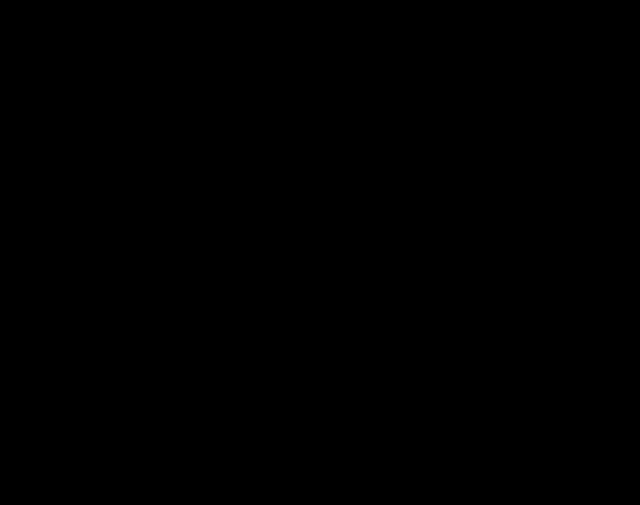

In [6]:
(Map("Mean UTCI by district")
 .fill(hot, "utci_mean", legend="mean UTCI (°C)", classes=5, tooltip=["name", "valid_coverage"])
 .outline(districts, label="name"))

## Exact coverage or cell centres?

For large zones the two rules agree. For small zones they do not: a 15 m buffer around each bus
stop covers only a few 10 m cells, and the centre rule keeps only the cells whose centres fall
inside. In exact mode `count` is the number of cells touched and `weighted_count` the sum of their
covered fractions, which equals the buffer's area in cells.

In [7]:
stops = td.bus_stops()
zones = stops.assign(geometry=stops.buffer(15))
exact = uw.zonal_stats(heat, zones, [uw.mean("utci", as_="utci"), uw.count(as_="cells"),
                                     uw.weighted_count(as_="covered")], zone_id="stop_id")
centre = uw.zonal_stats(heat, zones, [uw.mean("utci", as_="utci"), uw.count(as_="cells")], zone_id="stop_id", method="cell_center")
print("each buffer is", round(zones.area.iloc[0]), "m², that is", round(zones.area.iloc[0] / 100, 2), "cells of 100 m²")
pd.DataFrame({"stop": exact["stop_id"], "cells touched": exact["cells"], "cells covered": exact["covered"].round(2),
              "cell centres inside": centre["cells"], "UTCI exact": exact["utci"].round(2),
              "UTCI centre": centre["utci"].round(2)}).head(6)

each buffer is 706 m², that is 7.06 cells of 100 m²


,stop,cells touched,cells covered,cell centres inside,UTCI exact,UTCI centre
0,S00,16,7.06,4,27.44,27.39
1,S01,16,7.06,4,28.02,27.98
2,S02,16,7.06,4,27.88,27.83
3,S03,16,7.06,4,26.66,26.56
4,S04,16,7.06,4,30.3,30.37
5,S05,16,7.06,4,27.6,27.68


## Land cover shares

For a categorical raster, `shares` gives the area fraction of each class in each zone, weighted by
coverage. Here: built (1), green (2) and water (3).

In [8]:
mix = uw.zonal_stats(land, districts, [uw.shares("land_cover", as_="share")], zone_id="district_id")
mix = mix.rename(columns={"share_1": "built", "share_2": "green", "share_3": "water"})
mix[["name", "built", "green", "water", "coverage"]].round(3)

,name,built,green,water,coverage
0,Northgate,0.75,0.25,0.0,1.0
1,Old Town,0.919,0.081,0.0,1.0
2,Eastfield,0.912,0.088,0.0,1.0
3,Mill District,0.919,0.081,0.0,1.0
4,Riverside,0.772,0.073,0.154,1.0


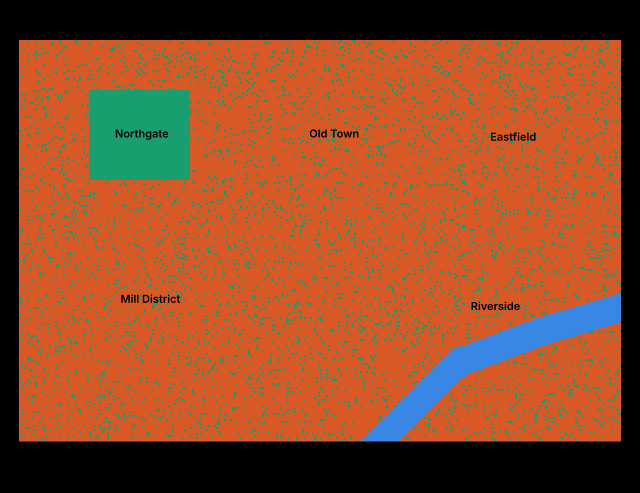

In [9]:
(Map("Land cover, 10 m cells")
 .raster(land, scheme="categorical", legend="land cover", labels={1: "built", 2: "green", 3: "water"},
         order=[3, 1, 2])
 .outline(districts, label="name", width=1.4))

## Zones partly outside the raster

Coverage is measured against each zone's full area, so a zone reaching past the raster's edge shows
it; a zone entirely outside gets coverage 0 and a missing mean rather than a made-up value.

In [10]:
from shapely.geometry import box
X, Y = td.X0, td.Y0
edge = td.gpd.GeoDataFrame({"zone_id": ["inside", "half out", "outside"]}, geometry=[
    box(X - 200, Y - 200, X + 200, Y + 200), box(X + 1300, Y - 200, X + 1700, Y + 200), box(X + 1800, Y, X + 2000, Y + 200)],
    crs=td.CRS)
uw.zonal_stats(heat, edge, [uw.mean("utci", as_="utci")], zone_id="zone_id").drop(columns="geometry").round(3)

,zone_id,utci,coverage,valid_coverage
0,inside,33.586,1.0,1.0
1,half out,27.589,0.5,0.5
2,outside,<NA>,0.0,0.0


**Next:** [6. Streets](06_streets.ipynb).